# How Predictable Are District Health Outcomes?
### A noise-aware, out-of-time test of forecasting on India's NFHS-6

**Team CodeFlow** (Saurav S, Shikshith V, Thijil Thejaswi M N, Vishwas V Angadi), ADA course project.

This notebook walks through the whole project and reproduces its main steps with the code in the
`nfhs_forecast` package of this repository:

1. **Data**: load the NFHS-4/5 file and the NFHS-6 compilation, clean them and match districts and indicators across rounds.
2. **Boundary harmonisation**: map changed districts with a lineage crosswalk and re-aggregate split districts with population weights.
3. **Noise model**: attach assumed sampling standard errors.
4. **Forecasting methods**: compare baselines, small-area models and machine learning, trained on NFHS-4 → NFHS-5.
5. **Cross-validation**: leave-one-state-out validation on NFHS-4 → NFHS-5.
6. **One-shot out-of-time test**: score the frozen models on NFHS-6.
7. **Analysis**: paired tests, structural break, conformal coverage, surprises.

> **Important.** The NFHS-6 evaluation is a pre-registered, one-shot test. It was run exactly once by
> `scripts/gate_b.ps1` (tag `freeze-v1`). This notebook **never re-runs it**; it loads the committed results.

**How to run:** open this notebook from the repository (root or `notebooks/` folder), with the project's
Python 3.11 environment (`.venv`) as the kernel, and choose *Run All*. It takes about a minute
(about 4 minutes if you set `RUN_CV = True`).

Runs locally from inside the repository, or on Google Colab: run the first code cell, then Runtime → Run all (about 1–2 minutes; saved NFHS-6 results are loaded, nothing is re-scored).

In [2]:
import os, sys, subprocess

REPO_URL = "https://github.com/Shikshith05/nfhs-district-forecast"
BRANCH = "main"

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("Command failed: " + cmd)

if not os.path.exists("config.yaml"):
    if not os.path.isdir("nfhs-district-forecast"):
        sh(f"git clone --branch {BRANCH} {REPO_URL}")
    os.chdir("nfhs-district-forecast")

try:
    import lightgbm, statsmodels, pyarrow, yaml, rapidfuzz
except ImportError:
    sh(f"{sys.executable} -m pip install -q -r requirements.txt")

needed = ["config.yaml", "nfhs_forecast", "data/raw", "data/lineage", "outputs/results_nfhs4to5.csv",
          "outputs/results_nfhs5to6.csv", "outputs/nfhs6_evaluation_run.json", "outputs/models/manifest.json",
          "outputs/post_run"]
missing = [p for p in needed if not os.path.exists(p)]
print("Working folder:", os.getcwd())
print("All required files found." if not missing else f"MISSING in this branch: {missing}")


Working folder: /content/nfhs-district-forecast
All required files found.


In [3]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

warnings.filterwarnings("ignore")
REPO = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
assert (REPO / "config.yaml").exists(), "Run the setup cell above first, or open this notebook from inside the repository"
sys.path.insert(0, str(REPO))

from nfhs_forecast.config import load_config
from nfhs_forecast import load, clean, match, noise, harmonise, models, evaluate

cfg = load_config(REPO / "config.yaml")
P = cfg["abs_paths"]
OUT = REPO / "outputs"
pd.set_option("display.width", 160, "display.max_columns", 20)
print("Repository:", REPO)

Repository: /content/nfhs-district-forecast


## 1. Data

* **NFHS-4 (2015-16) and NFHS-5 (2019-21):** district fact-sheet values; the NFHS-5 fact sheets print the comparable NFHS-4 value beside each NFHS-5 value (`data/raw/nfhs4_5/India.csv`).
* **NFHS-6 (2023-24):** provisional IIPS district fact sheets, as compiled by Patra (2026) (`data/raw/nfhs6/`).

In [4]:
raw45 = load.read_nfhs45(P["nfhs45_csv"])
raw6 = load.read_nfhs6(P["nfhs6_csv"])
geo = load.read_geo_properties(P["geojson"])
print(f"NFHS-4/5 file: {len(raw45):,} rows | NFHS-6 compilation: {len(raw6):,} rows")
raw45.head()

NFHS-4/5 file: 73,632 rows | NFHS-6 compilation: 66,519 rows


,State,ST_CEN_CD,District,DISTRICT,DT_CEN_CD,Category,Indicator,NFHS 5,NFHS 4
0,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Female population age 6 years and above who ev...,78,77.2
1,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Population below age 15 years (%),23,25.4
2,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Sex ratio of the total population (females per...,973,957
3,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Sex ratio at birth for children born in the la...,927,1060
4,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Population and Household Profile,Children under age 5 years whose birth was reg...,98,99.3


### 1.1 Cleaning

`India.csv` writes missing and suppressed cells as `0`. The cleaner reclassifies these zeros: a whole
district-round missing, an indicator not measured in that round, a suppressed value, or a true zero.
NFHS-6 `*` cells (fewer than 25 cases) are treated as suppressed.

In [5]:
l45, log45 = clean.clean_nfhs45(raw45, cfg, geo)
d6, log6 = clean.clean_nfhs6(raw6, cfg)
print("NFHS-4/5 long table:", l45.shape, "| NFHS-6 table:", d6.shape)
pd.Series({k: v for k, v in log45.items() if isinstance(v, (int, float))}, name="NFHS-4/5 cleaning log").to_frame()

NFHS-4/5 long table: (147054, 10) | NFHS-6 table: (66139, 14)


,NFHS-4/5 cleaning log
raw_rows,73632
raw_districts,707
raw_indicator_texts,105
excluded_rows,104
duplicate_rows_dropped,2
districts_with_census_code,643
clean_districts,707


### 1.2 Matching indicators and districts across rounds

Indicators are matched by normalised text. Districts are matched by name, with aliases and fuzzy matching.
The two copies of NFHS-5 (in `India.csv` and in the NFHS-6 file's own NFHS-5 column) are then audited
against each other. Districts and indicators that disagree are excluded.

In [6]:
variants, cross = match.build_indicator_matching(l45, d6, cfg)
name_map = match.match_districts(l45, d6, cfg)
audit_pairs, audit_summary, audit_by, audit_by_ind = match.audit_nfhs5(
    l45, d6, variants, name_map, cross, cfg["indicators"]["min_audit_agreement"],
    district_indicators=set(cross.loc[cross.core, "indicator_id"]))
name_map = match.finalise_district_status(name_map, audit_by, cfg)
core_uids = sorted(name_map.loc[name_map.core, "district_uid"])
print(f"Districts with stable boundaries and a clean audit (core): {len(core_uids)}")
print(f"NFHS-5 audit: {audit_summary['within_0_5_agreement_rate']:.1%} of value pairs agree within 0.5 pp")

panel = match.build_panel_long(l45, d6, variants, name_map)
codebook = match.build_codebook(cross, panel, set(core_uids), cfg, audit_by_ind)
included = codebook.loc[codebook.include, "indicator_id"].tolist()
print(f"Indicators used: {len(included)}")
codebook.loc[codebook.include, ["indicator_id", "domain"]].groupby("domain").indicator_id.apply(", ".join).to_frame("indicators")

Districts with stable boundaries and a clean audit (core): 547
NFHS-5 audit: 96.8% of value pairs agree within 0.5 pp
Indicators used: 23


,indicators
domain,
child_health,"diarrhoea, early_bf, full_vacc, mcv1, vitamin_a"
maternal_care,"anc_4plus, anc_first_trimester, csection, ifa_..."
nutrition,"stunting, underweight, wasting, women_overweig..."
wash,"menstrual_hygiene, water_improved"
women_empowerment,"child_marriage, fp_modern, teen_pregnancy, unm..."


## 2. Noise model and boundary harmonisation

**Noise model.** Fact sheets do not publish sample sizes, so each value gets an *assumed* standard error
$\mathrm{SE} = 100\sqrt{p(1-p)\,\mathrm{deff}/n}$, with design effect 2.0.

**Harmonisation.** District boundaries changed between rounds. A lineage crosswalk links every parent
district to its children, with a source and a confidence level. Each connected component of the
bipartite parent–child graph becomes one analysis unit. When an NFHS-5 district $P$ was split into
NFHS-6 districts $C_i$, the NFHS-6 value on NFHS-5 boundaries is the population-weighted average

$$\hat y_P = \sum_i w_i\, y_{C_i}, \qquad w_i = N_{C_i} / \sum_j N_{C_j},$$

using Census-2011 populations. The standard error is propagated as
$\sum_i w_i^2 \mathrm{SE}_{C_i}^2$, plus a term for uncertainty in the weights. Official lineage for 13
split districts is in `data/lineage/` (DECISIONS D41).

In [7]:
node_panel = panel[panel.district_uid.notna() & panel.indicator_id.isin(included)]
node_panel = noise.add_se(node_panel, codebook, cfg)
codes = (panel[panel["round"] == 5].dropna(subset=["district_code"])
         .groupby("district_uid").district_code.first().to_dict())
supplied = harmonise.load_supplied(cfg)
crosswalk = harmonise.build_crosswalk(name_map, cfg, codes)
crosswalk, problems = harmonise.apply_supplied_lineage(crosswalk, supplied["lineage"], name_map, cfg)
model_panel, units, crosswalk = harmonise.harmonise_panel(node_panel, name_map, crosswalk, cfg, supplied)

print("Training units (NFHS-4 -> NFHS-5):", int(units.train_unit.sum()))
print("Test units (NFHS-5 -> NFHS-6):    ", int(units.test_unit.sum()))
print("Stable-boundary subset:            ", int((units.stable_unit & units.train_unit).sum()))
units[units.test_unit].unit_type.value_counts().to_frame("test units by type")

Training units (NFHS-4 -> NFHS-5): 571
Test units (NFHS-5 -> NFHS-6):     686
Stable-boundary subset:             547


,test units by type
unit_type,
identity,668
aggregated,11
inherited_remnant,5
inherited_child,2


In [8]:
pops = supplied["population"]
pops[pops.state.eq("Tamil Nadu") & pops.district.isin(["Vellore", "Ranipet", "Tirupathur"])][
    ["state", "district", "population"]].assign(weight=lambda d: d.population / d.population.sum())

,state,district,population,weight
4,Tamil Nadu,Vellore,1614242,0.410088
5,Tamil Nadu,Ranipet,1210277,0.307463
6,Tamil Nadu,Tirupathur,1111812,0.282449


### 2.1 Reproducibility check

The models were frozen with a hash of the training data. Rebuilding the training panel from the raw files
must reproduce the same hash.

In [9]:
train_uids = sorted(units.loc[units.train_unit, "unit_uid"])
stable_uids = sorted(units.loc[units.stable_unit & units.train_unit, "unit_uid"])
train_panel = model_panel[model_panel["round"].isin([4, 5]) & model_panel.district_uid.isin(train_uids)].copy()
models.assert_no_round6(train_panel, "notebook")

manifest = json.loads((OUT / "models" / "manifest.json").read_text())
h = models.training_data_hash(train_panel)
print("Training-data hash, rebuilt now:", h)
print("Training-data hash, frozen     :", manifest["train_hash"])
print("MATCH" if h == manifest["train_hash"] else "MISMATCH: the data or code changed")

Training-data hash, rebuilt now: d3f06bee428deeef
Training-data hash, frozen     : d3f06bee428deeef
MATCH


## 3. Why regression to the mean is the baseline to beat

District estimates are noisy. A district that was measured unusually high in one round tends to be
measured lower in the next, even if nothing changed. **Regression to the mean (RTM)** fits
$\hat y_{t+1} = a + b\, y_t$ per indicator. A slope $b < 1$ pulls extreme districts back towards the
mean. Below, RTM is shown on NFHS-4 → NFHS-5 for one indicator.

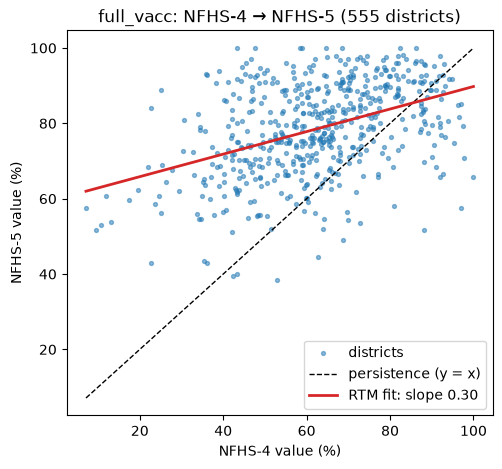

In [10]:
ind = "full_vacc"
w = train_panel[train_panel.indicator_id == ind].pivot_table(index="district_uid", columns="round", values="value").dropna()
b, a = np.polyfit(w[4], w[5], 1)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(w[4], w[5], s=8, alpha=0.5, label="districts")
xs = np.linspace(w[4].min(), w[4].max(), 50)
ax.plot(xs, xs, "k--", lw=1, label="persistence (y = x)")
ax.plot(xs, a + b * xs, "C3", lw=2, label=f"RTM fit: slope {b:.2f}")
ax.set_xlabel("NFHS-4 value (%)"); ax.set_ylabel("NFHS-5 value (%)")
ax.set_title(f"{ind}: NFHS-4 → NFHS-5 ({len(w)} districts)"); ax.legend()
plt.show()

## 4. Methods

| Family | Methods |
|---|---|
| Baselines | persistence; national trend; state trend; RTM |
| Small-area | Fay–Herriot with state effects; RTM on Fay–Herriot-denoised inputs (FH + RTM) |
| Machine learning | elastic net and LightGBM predicting the change from own history, other indicators, spatial-neighbour features, state mean, region and state dummies |
| Ablations | own history only; + other indicators; + spatial; full; full without state dummies |

**Skill** = 1 − MSE(method) / MSE(persistence), so 0 means no better than "nothing changes". Confidence
intervals come from a bootstrap that resamples whole states.

## 5. Cross-validation on NFHS-4 → NFHS-5

Leave-one-state-out (LOSO) cross-validation holds out one state at a time. It takes about 3–4 minutes,
so by default the notebook loads the committed results. Set `RUN_CV = True` to recompute them.

In [11]:
RUN_CV = False

if RUN_CV:
    from nfhs_forecast import spatial
    adjacency = spatial.load_adjacency(P["geojson"])
    ev = cfg["evaluation"]
    preds = evaluate.loso_cv(train_panel, included, train_uids, cfg, verbose=False,
                             adjacency=adjacency, feature_sets=cfg["models"]["feature_sets"])
    res45 = evaluate.metric_table(preds, evaluate.METHOD_ORDER, bootstrap_reps=ev["bootstrap_reps"],
                                  ci_level=ev["ci_level"], seed=cfg["random_seed"])
else:
    res45 = pd.read_csv(OUT / "results_nfhs4to5.csv")

MAIN = ["persistence", "national_trend", "state_trend", "rtm", "fay_herriot", "fh_rtm",
        "elastic_net", "lightgbm", "elastic_net__nostate", "lightgbm__nostate"]
def overall(res):
    o = res[res.indicator_id == "OVERALL"].set_index("method")
    return o.loc[[m for m in MAIN if m in o.index], ["skill", "skill_lo", "skill_hi"]].round(3)
overall(res45)

,skill,skill_lo,skill_hi
method,,,
persistence,0.000,0.000,0.000
national_trend,0.422,0.326,0.478
state_trend,0.422,0.326,0.478
rtm,0.613,0.535,0.672
fay_herriot,0.083,0.072,0.098
fh_rtm,0.624,0.551,0.678
elastic_net,0.638,0.566,0.690
lightgbm,0.630,0.553,0.687
elastic_net__nostate,0.625,0.554,0.677


In [12]:
pd.read_csv(OUT / "paired_summary_nfhs4to5.csv").round(3)

,comparison,indicators,better_raw,significantly_better,significantly_worse,overall_diff_mse,overall_diff_lo,overall_diff_hi,overall_p
0,elastic_net vs rtm,23,19,2,0,-4.926,-7.712,-2.005,0.000
1,elastic_net__nostate vs rtm,23,15,0,0,-2.449,-6.244,1.199,0.210
2,lightgbm vs rtm,23,16,0,0,-3.448,-8.261,1.733,0.184
3,lightgbm__nostate vs rtm,23,15,0,0,-2.839,-7.660,2.274,0.260


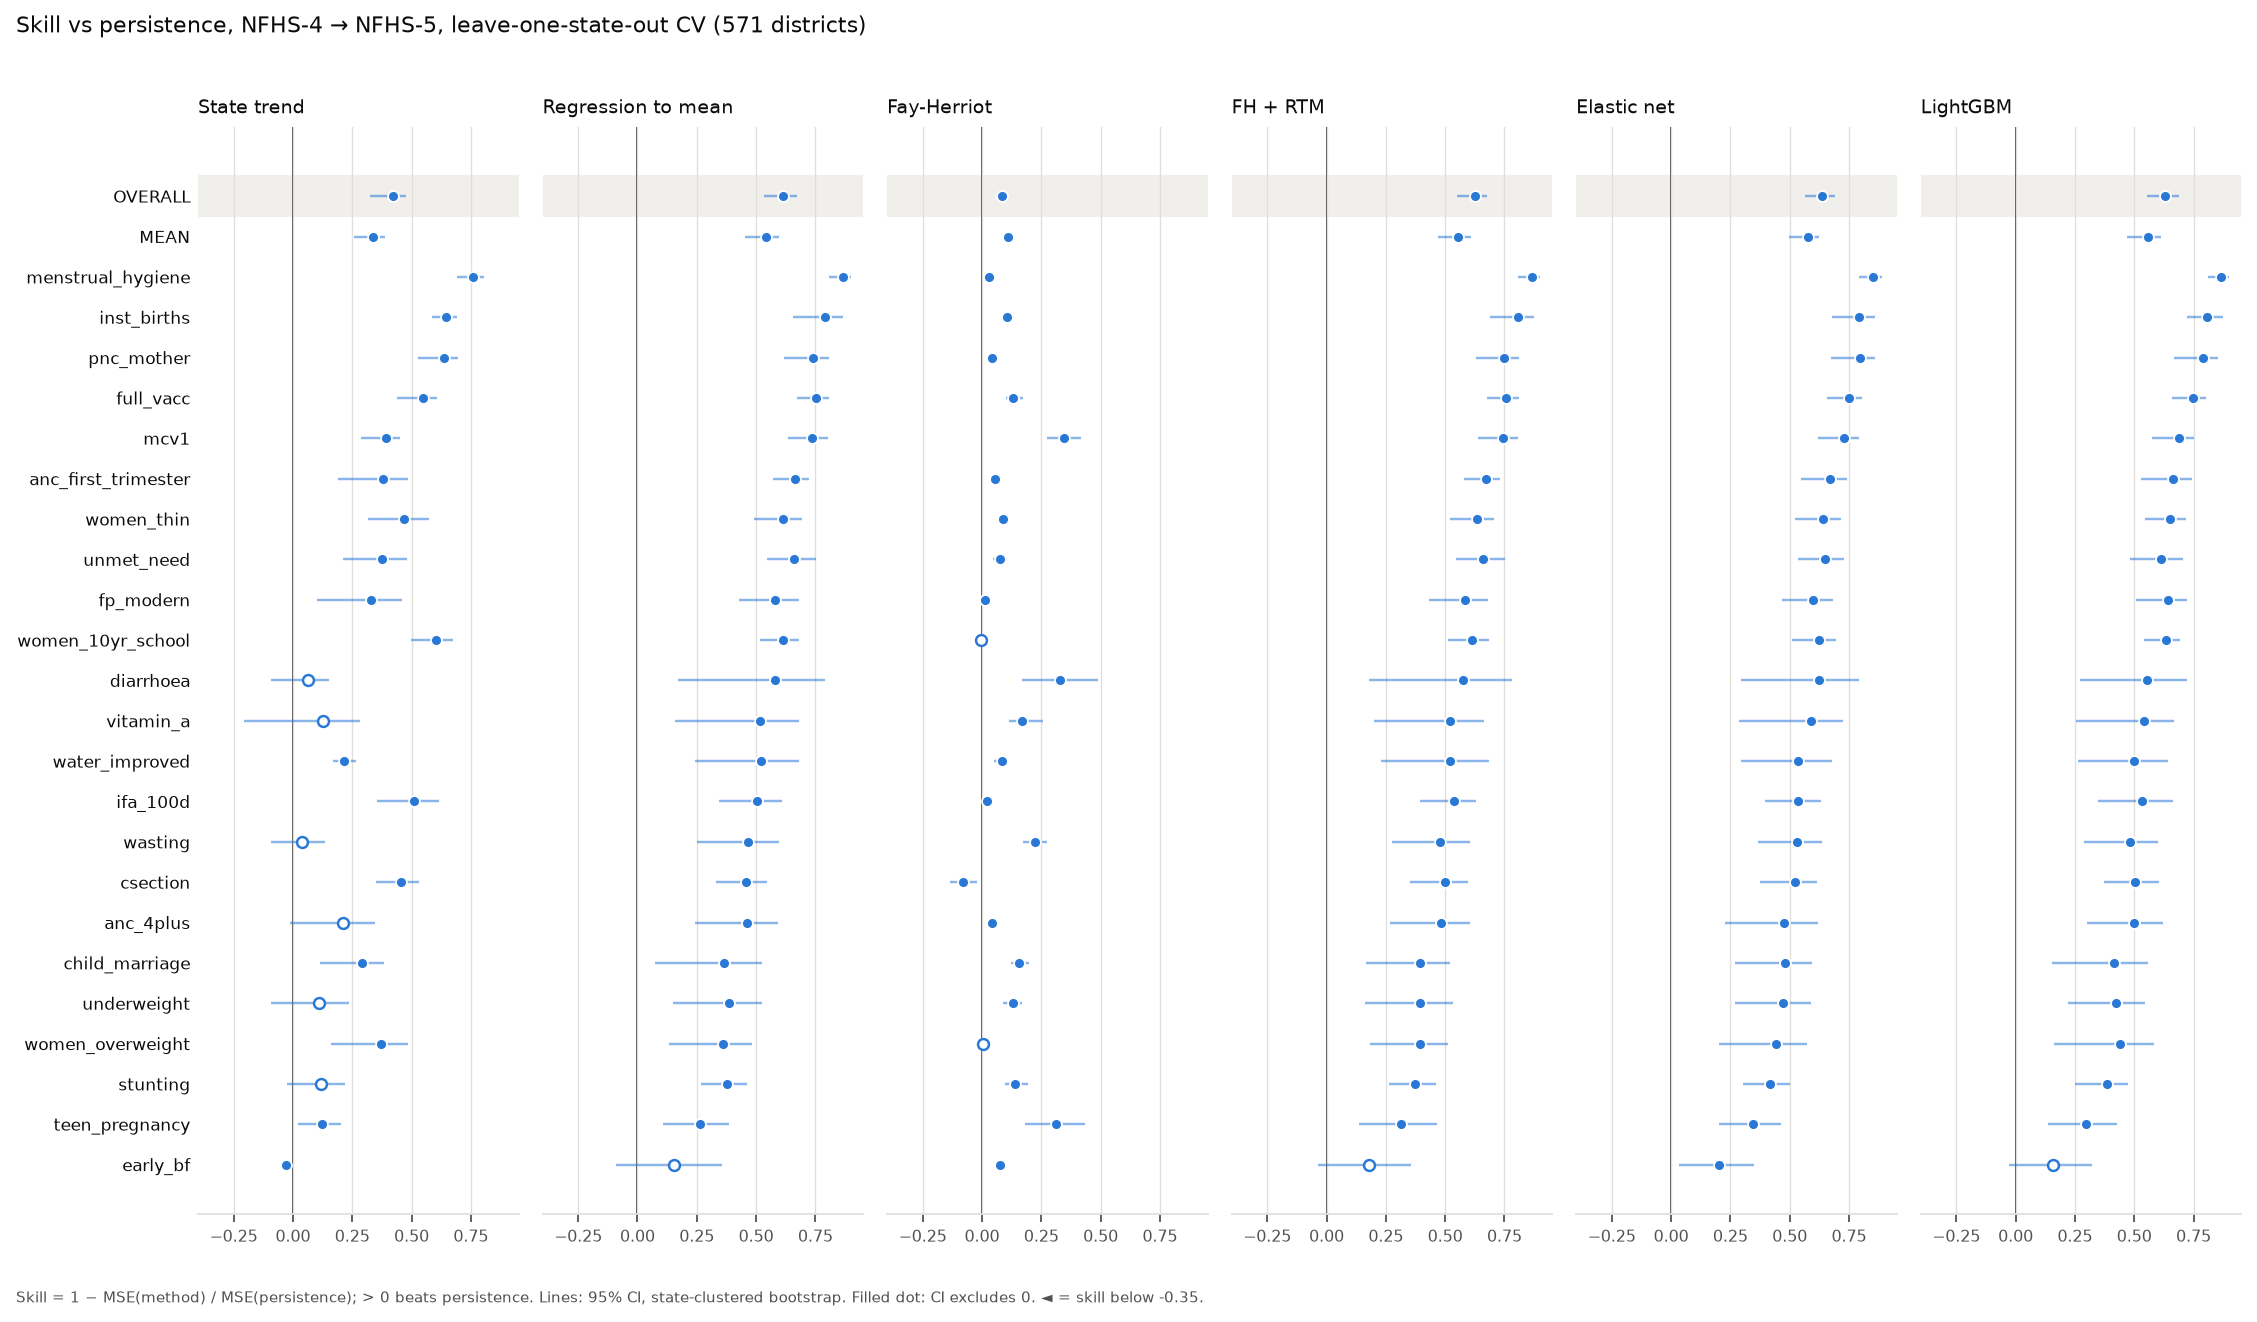

In [13]:
display(Image(filename=str(OUT / "skill_by_indicator.png"), width=900))

**Cross-validation result.** The elastic net beat RTM on pooled error (skill 0.637 vs 0.613), but it was
significantly better on only 2 of 23 indicators. Most of every method's skill comes from the average
national change between rounds.

## 6. The one-shot out-of-time test on NFHS-6

The models trained on NFHS-4 → NFHS-5 were frozen and tagged (`freeze-v1`). They then predicted NFHS-6
from NFHS-5 **once**. Below is the run log and the committed results; nothing is re-scored here.

In [14]:
run = json.loads((OUT / "nfhs6_evaluation_run.json").read_text())
{k: run[k] for k in ["status", "freeze_tag", "train_hash", "hash_check", "started_utc", "outcome"]}

{'status': 'completed',
 'freeze_tag': 'freeze-v1',
 'train_hash': 'd3f06bee428deeef',
 'hash_check': True,
 'started_utc': '2026-11-11T09:34:13+00:00',
 'outcome': 'scored'}

In [15]:
res56 = pd.read_csv(OUT / "results_nfhs5to6.csv")
cmp = overall(res45)[["skill"]].rename(columns={"skill": "CV 4→5"}).join(
      overall(res56).rename(columns={"skill": "Test 5→6", "skill_lo": "test lo", "skill_hi": "test hi"}))
cmp

,CV 4→5,Test 5→6,test lo,test hi
method,,,,
persistence,0.000,0.000,0.000,0.000
national_trend,0.422,-0.041,-0.174,0.095
state_trend,0.422,-0.495,-0.717,-0.264
rtm,0.613,0.293,0.228,0.361
fay_herriot,0.083,0.119,0.104,0.132
fh_rtm,0.624,0.296,0.224,0.372
elastic_net,0.638,0.169,0.068,0.275
lightgbm,0.630,0.252,0.172,0.332
elastic_net__nostate,0.625,0.268,0.167,0.366


In [16]:
pd.read_csv(OUT / "paired_summary_nfhs5to6.csv").round(3)

,comparison,indicators,better_raw,significantly_better,significantly_worse,overall_diff_mse,overall_diff_lo,overall_diff_hi,overall_p
0,elastic_net vs rtm,23,5,0,10,13.356,7.222,19.452,0.000
1,elastic_net__nostate vs rtm,23,12,3,4,2.725,-1.995,7.614,0.322
2,lightgbm vs rtm,23,7,2,4,4.418,1.078,7.646,0.008
3,lightgbm__nostate vs rtm,23,7,2,3,5.012,1.133,9.120,0.008


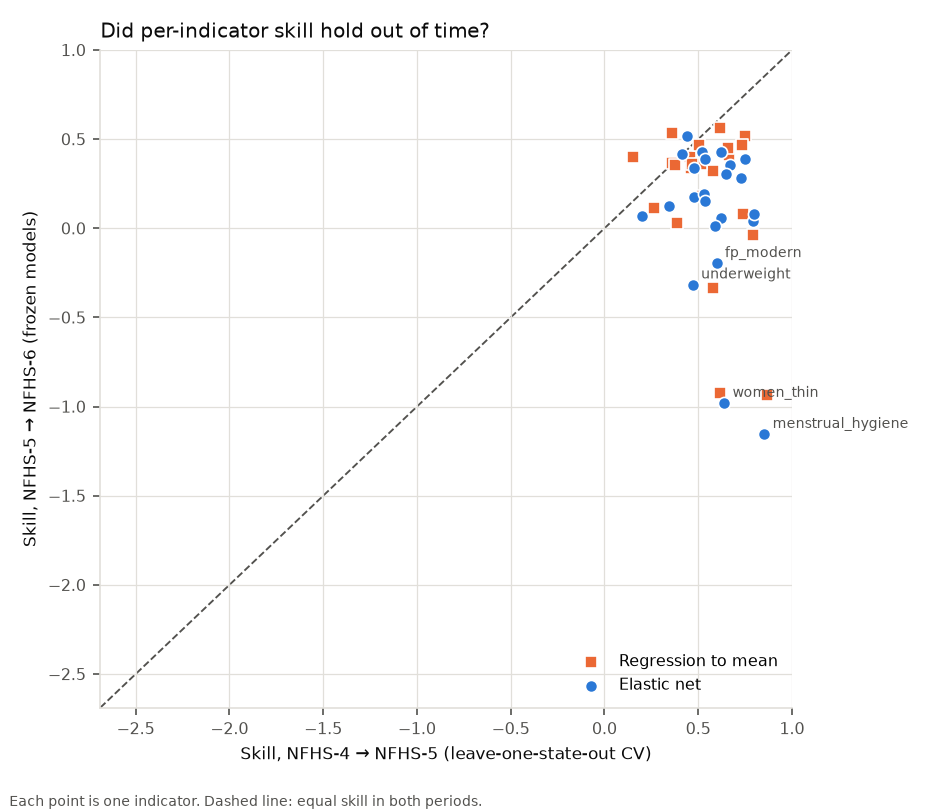

In [17]:
display(Image(filename=str(OUT / "post_run" / "comparison_45_vs_56.png"), width=600))

**Test result.** Every method lost skill out of time. The pre-registered primary method (elastic net)
fell to 0.169 and had **significantly higher error than RTM** (0.293). The trend baselines dropped below
persistence.

## 7. Why did skill fall? Structural break (exploratory)

For each indicator, compare the two transitions: did the **mean change**, the **RTM slope** or the
**error scale** change significantly?

In [18]:
sb = pd.read_csv(OUT / "post_run" / "structural_break.csv")
print(f"Indicators with a break in the mean change: {int(sb.shift_break.sum())} of {len(sb)}")
print(f"Indicators with a break in the RTM slope:   {int(sb.slope_break.sum())} of {len(sb)}")
sb.loc[sb.shift_break, ["indicator_id", "shift_45", "shift_56", "shift_diff"]].round(1).sort_values("shift_diff")

Indicators with a break in the mean change: 12 of 23
Indicators with a break in the RTM slope:   2 of 23


,indicator_id,shift_45,shift_56,shift_diff
11,menstrual_hygiene,19.7,3.4,-16.3
12,pnc_mother,17.1,3.8,-13.3
6,fp_modern,10.1,-3.1,-13.2
7,full_vacc,16.2,5.2,-11.0
9,inst_births,9.7,2.1,-7.6
1,anc_first_trimester,11.9,4.9,-7.0
10,mcv1,8.2,3.1,-5.1
13,stunting,-2.8,-5.6,-2.8
19,water_improved,2.5,0.6,-1.9
14,teen_pregnancy,-1.3,-0.2,1.1


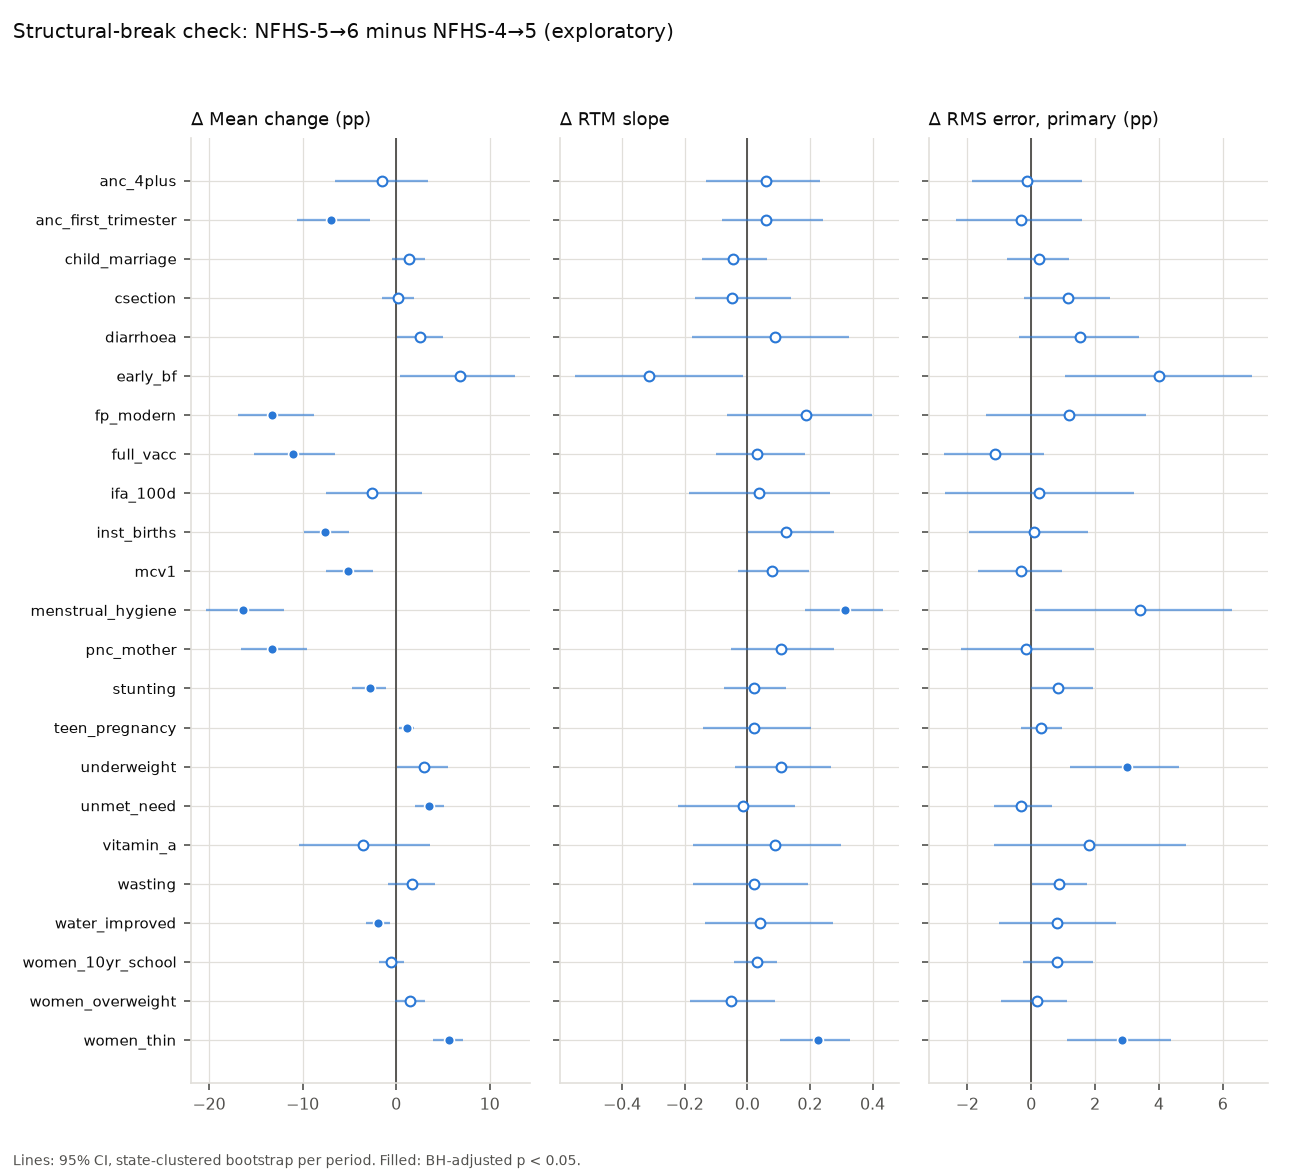

In [19]:
display(Image(filename=str(OUT / "post_run" / "structural_break.png"), width=900))

The average rate of change dropped sharply for several programme indicators: modern contraception, full
vaccination, postnatal care, institutional births and menstrual hygiene. The **slope** of mean reversion
hardly changed. Models that learned the size of the 2015→2020 gains overshot. RTM's "pull back towards
the mean" kept working.

The state dummies made it worse. State-level changes did not persist, and leave-one-state-out
cross-validation could not detect this, because it never scores a state whose effect it estimated.

## 8. Uncertainty and surprises

In [20]:
cov = pd.read_csv(OUT / "post_run" / "coverage.csv")
cov[cov.indicator_id.eq("OVERALL") & cov.subset.eq("all")][["variant", "method", "coverage", "mean_width", "nominal"]].round(3)

,variant,method,coverage,mean_width,nominal
0,normalised,elastic_net,0.844,24.223,0.9
24,normalised,fh_rtm,0.873,24.664,0.9
48,normalised,lightgbm,0.866,24.496,0.9
72,normalised,rtm,0.877,24.878,0.9
96,split,elastic_net,0.850,25.036,0.9
120,split,fh_rtm,0.879,25.518,0.9
144,split,lightgbm,0.871,25.380,0.9
168,split,rtm,0.882,25.858,0.9
192,weighted,elastic_net,0.841,24.303,0.9
216,weighted,fh_rtm,0.866,24.775,0.9


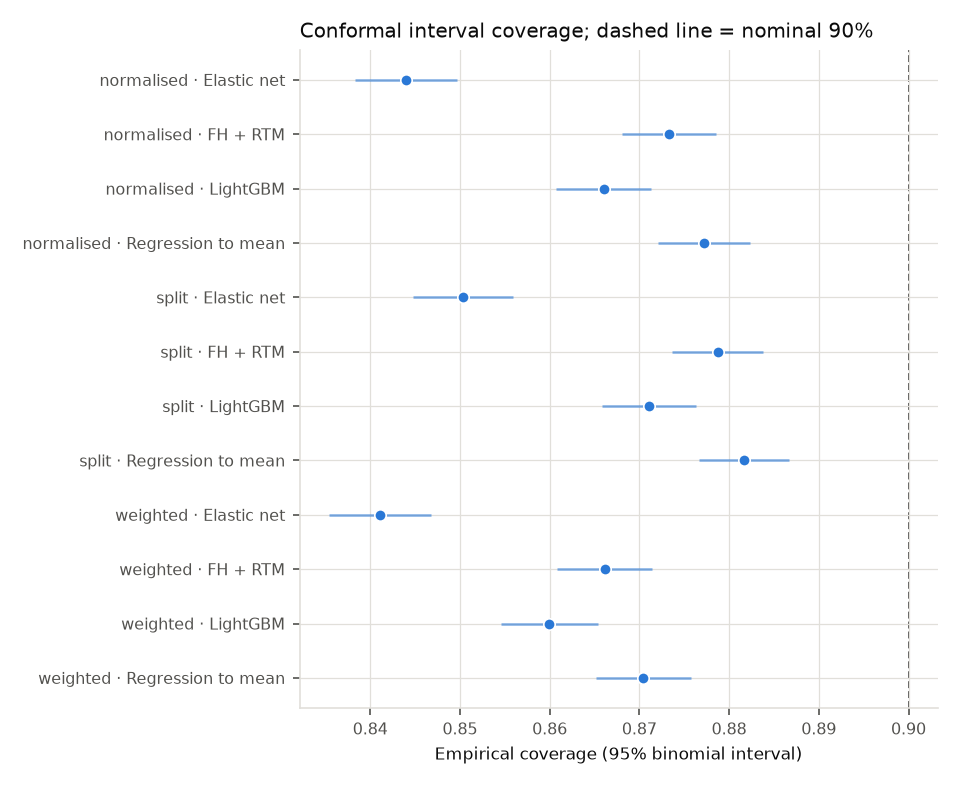

In [21]:
display(Image(filename=str(OUT / "post_run" / "coverage.png"), width=600))

In [22]:
s = pd.read_csv(OUT / "post_run" / "surprise_summary.csv")
s[["method", "tests", "surprises_normal", "naive_k", "overlap_naive_vs_bh", "naive_topk_mean_se_true", "bh_mean_se_true"]]

,method,tests,surprises_normal,naive_k,overlap_naive_vs_bh,naive_topk_mean_se_true,bh_mean_se_true
0,elastic_net,15712,138,138,25,4.35809,2.94546
1,rtm,15712,62,62,12,4.02440,2.82699


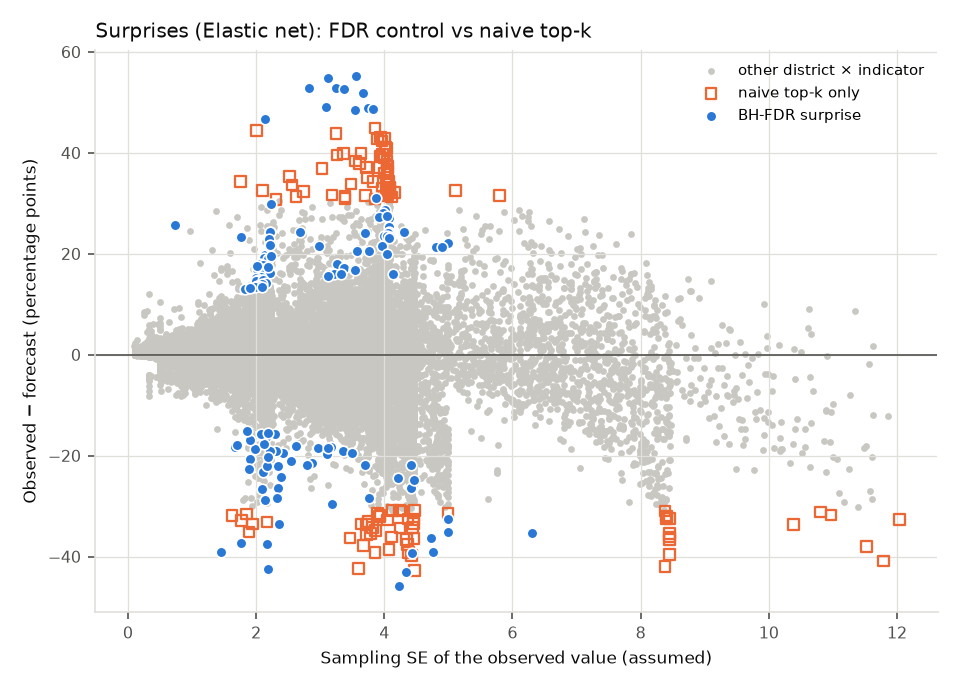

In [23]:
display(Image(filename=str(OUT / "post_run" / "surprises.png"), width=650))

A naive "largest residuals" list mostly picks **noisy** districts (mean SE 4.36 pp vs 2.95 pp for the
FDR-controlled list), so noise-aware testing matters.

## 9. Forecastability: indicator or district?

In [24]:
pd.read_csv(OUT / "post_run" / "forecastability_decomposition.csv").round(3)

,run_mode,method,n,districts,indicators,r2_indicator_only,r2_district_only,r2_additive,unique_indicator,unique_district
0,NFHS6,elastic_net,15712,686,23,0.061,0.075,0.136,0.061,0.075


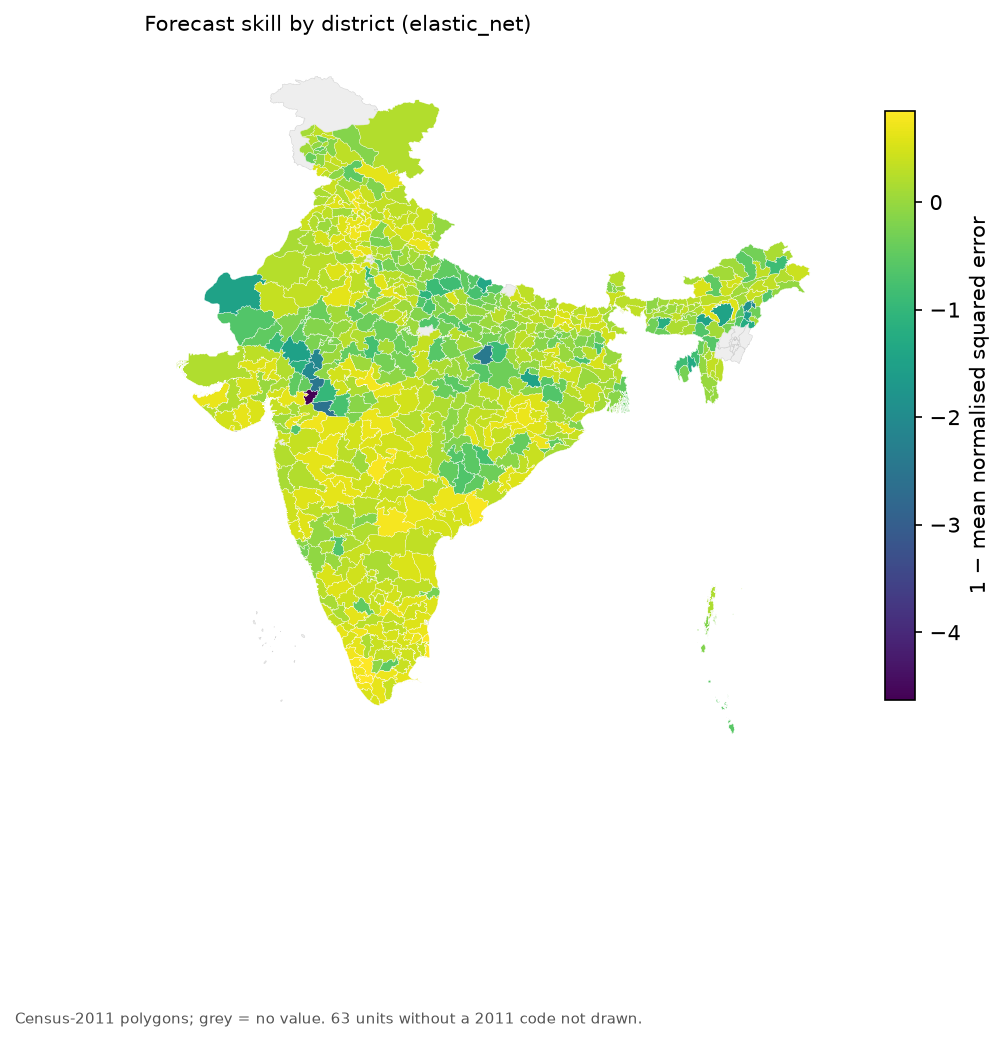

In [25]:
display(Image(filename=str(OUT / "post_run" / "map_skill.png"), width=650))

## 10. Conclusions

* District outcomes are only partly forecastable one survey round ahead. RTM kept about 0.29 skill over
  persistence out of time.
* Machine learning won in cross-validation but lost the pre-registered one-shot test. Its advantage
  rested on state effects that did not transfer across periods.
* The main driver was a **break in the national rate of change** of programme indicators, not in mean
  reversion.
* Intervals calibrated on one transition under-covered the next (84–88% vs nominal 90%).
* **Recommendation:** use RTM (or FH + RTM) as the default for district forecasts. With NFHS-6 published,
  two transitions are now available to learn how the national shift itself changes.

Full details: `docs/report.md`, decisions in `DECISIONS.md`, harmonised data in `outputs/release/`.